# Лабораторная работа №2 — Кластеризация

Credit Risk Dataset. Ноутбук содержит вычислительный код и сохранённые результаты эксперимента. Выполняйте ячейки сверху вниз. По умолчанию показываются ранее рассчитанные результаты; для повторного обучения установите `REBUILD = True` (расчёт может занять несколько минут).

In [2]:
from pathlib import Path
import sys, os, json
import pandas as pd
from IPython.display import display, Image, Markdown

PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/raw/credit_risk_dataset.csv').exists()), None)
if PROJECT is None:
    raise RuntimeError('Откройте ноутбук из папки проекта ОМО')
LAB = PROJECT / 'Лаба2'
sys.path.insert(0, str(LAB))
REBUILD = False


## Данные и очистка
Одна строка — кредит. Удаляем строки с пропусками и полные дубликаты. В моделях масштабирование и кодирование выполняются отдельно от этой демонстрации.

In [4]:
raw = pd.read_csv(PROJECT / 'data/raw/credit_risk_dataset.csv')
display(raw.head())
display(raw.isna().sum().rename('Пропуски').to_frame())
clean = raw.dropna().drop_duplicates()
print(f'Исходных строк: {len(raw)}; после очистки: {len(clean)}')


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


,Пропуски
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


Исходных строк: 32581; после очистки: 28501


## Подготовка моделей
loan_status исключён из признаков. Все методы используют одни 4000 объектов. Число кластеров и параметры выбираются по silhouette со штрафом за шум. ARI/AMI рассчитываются после выбора. PCA используется только для рисунка.

In [6]:
__file__ = str(LAB / 'clustering.py')
"""Лабораторная №2. Запуск: python Лаба2/clustering.py."""

import os
from pathlib import Path
import json

ROOT = Path(__file__).resolve().parent
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
os.environ.setdefault("OMP_NUM_THREADS", "2")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             adjusted_mutual_info_score, homogeneity_score,
                             completeness_score)
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUMERIC = ["person_age", "person_income", "person_emp_length", "loan_amnt",
           "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"]
TARGET = "loan_status"
OUTPUT = ROOT / "reports"


def save(name):
    plt.tight_layout()
    plt.savefig(OUTPUT / name, dpi=150, bbox_inches="tight")
    plt.close()


def internal_score(x, labels):
    """Шум исключён из silhouette; coverage учитывает его долю отдельно."""
    mask = labels != -1
    count = len(np.unique(labels[mask]))
    coverage = float(mask.mean())
    if count < 2 or count >= mask.sum():
        return count, coverage, None
    # Фиксированная подвыборка ограничивает стоимость попарных расстояний.
    try:
        score = float(silhouette_score(x[mask], labels[mask],
                                      sample_size=min(1500, int(mask.sum())), random_state=42))
    except ValueError:
        score = None
    return count, coverage, score



## Обучение и подбор параметров
Ниже приведено тело вычислительной программы, разбитое на последовательные ячейки. При `REBUILD=False` обучение пропускается. Для полного повторного расчёта измените флаг в первой ячейке и выполните Restart Kernel and Run All.

In [8]:
if REBUILD:
    OUTPUT.mkdir(parents=True, exist_ok=True)

In [9]:
if REBUILD:
    sns.set_theme(style="whitegrid")

In [10]:
if REBUILD:
    source = ROOT.parent / "data/raw/credit_risk_dataset.csv"

In [11]:
if REBUILD:
    raw = pd.read_csv(source)

In [12]:
if REBUILD:
    complete = raw.dropna()

In [13]:
if REBUILD:
    clean = complete.drop_duplicates()

In [14]:
if REBUILD:
    data = clean.sample(n=min(4000, len(clean)), random_state=42).copy()

In [15]:
if REBUILD:
    features = data.drop(columns=TARGET)

In [16]:
if REBUILD:
    categories = [name for name in features if name not in NUMERIC]

In [17]:
if REBUILD:
    encoder = ColumnTransformer([
        ("numeric", StandardScaler(), NUMERIC),
        ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categories),
    ])

In [18]:
if REBUILD:
    x = encoder.fit_transform(features)

In [19]:
if REBUILD:
    candidates, selected = [], {}

In [20]:
if REBUILD:
    for method in ["KMeans", "DBSCAN", "Hierarchical"]:
        print(f"Selecting {method}...", flush=True)
        best_value = -np.inf
        configs = ([{"n_clusters": k} for k in range(2, 9)] if method == "KMeans"
                   else [{"eps": eps, "min_samples": n}
                         for eps in [0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.5, 3.0] for n in [3, 5, 10, 25]]
                   if method == "DBSCAN" else
                   [{"n_clusters": k, "linkage": how} for k in range(2, 9)
                    for how in ["ward", "average"]])
        for config in configs:
            model = (KMeans(**config, random_state=42, n_init=10) if method == "KMeans"
                     else DBSCAN(**config, n_jobs=2) if method == "DBSCAN"
                     else AgglomerativeClustering(**config))
            labels = model.fit_predict(x)
            count, coverage, silhouette = internal_score(x, labels)
            # DBSCAN: не допускаем выбора малого островка с высоким silhouette.
            valid = silhouette is not None and coverage >= 0.5
            value = silhouette - (1 - coverage) if valid else None
            candidates.append({"method": method, "parameters": json.dumps(config),
                               "clusters": count, "coverage": coverage,
                               "silhouette": silhouette, "selection_score": value})
            if value is not None and value > best_value:
                best_value = value
                selected[method] = (labels.copy(), config)
        if method not in selected:
            pd.DataFrame(candidates).to_csv(OUTPUT / "parameter_search.csv", index=False)
            raise RuntimeError(f"No valid {method} partition: inspect grid and representation")
        print(method, selected[method][1], flush=True)

In [21]:
if REBUILD:
    pd.DataFrame(candidates).to_csv(OUTPUT / "parameter_search.csv", index=False)

In [22]:
if REBUILD:
    pca = PCA(n_components=2, random_state=42)

In [23]:
if REBUILD:
    points = pca.fit_transform(x)

In [24]:
if REBUILD:
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

In [25]:
if REBUILD:
    sns.scatterplot(x=points[:, 0], y=points[:, 1], hue=data[TARGET].to_numpy(),
                    palette="Set1", s=14, alpha=0.5, ax=axes[0, 0])

In [26]:
if REBUILD:
    axes[0, 0].set_title("Real classes: loan_status")

In [27]:
if REBUILD:
    metrics, profiles, comparisons = [], [], []

In [28]:
if REBUILD:
    predictions = pd.DataFrame({"source_row": data.index, "actual": data[TARGET].to_numpy(),
                                "PCA1": points[:, 0], "PCA2": points[:, 1]})

In [29]:
if REBUILD:
    for ax, (method, (labels, config)) in zip(list(axes.flat)[1:], selected.items()):
        count, coverage, silhouette = internal_score(x, labels)
        y = data[TARGET].to_numpy()
        metrics.append({"method": method, "clusters": count, "coverage": coverage,
                        "noise_rows": int((labels == -1).sum()), "silhouette": silhouette,
                        "ARI": adjusted_rand_score(y, labels),
                        "AMI": adjusted_mutual_info_score(y, labels),
                        "homogeneity": homogeneity_score(y, labels),
                        "completeness": completeness_score(y, labels)})
        predictions[method] = labels
        sns.scatterplot(x=points[:, 0], y=points[:, 1], hue=labels.astype(str),
                        palette="tab10", alpha=0.5, s=14, ax=ax)
        ax.set_title(method + " (-1 = noise)")
        grouped = data.assign(cluster=labels).groupby("cluster")
        summary = grouped[NUMERIC].mean()
        summary["rows"] = grouped.size()
        summary["default_rate"] = grouped[TARGET].mean()
        for category in categories:
            summary[category + "_mode"] = grouped[category].agg(lambda s: s.mode().iloc[0])
        summary.insert(0, "method", method)
        profiles.append(summary.reset_index())
        cross = pd.crosstab(labels, y).reindex(columns=[0, 1], fill_value=0)
        cross.index.name = "cluster"
        cross.insert(0, "method", method)
        comparisons.append(cross.reset_index())

In [30]:
if REBUILD:
    for ax in axes.flat:
        ax.set_xlabel("PCA1")
        ax.set_ylabel("PCA2")

In [31]:
if REBUILD:
    save("partitions_pca.png")

In [32]:
if REBUILD:
    fig, axes = plt.subplots(1, 3, figsize=(17, 6))

In [33]:
if REBUILD:
    for ax, (method, (labels, _)) in zip(axes, selected.items()):
        table = pd.crosstab(labels, data[TARGET].to_numpy()).reindex(columns=[0, 1], fill_value=0)
        sns.heatmap(table, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
        ax.set_title(method)
        ax.set_xlabel("Real class")
        ax.set_ylabel("Cluster (-1 = noise)")

In [34]:
if REBUILD:
    save("classes_comparison.png")

In [35]:
if REBUILD:
    plt.figure(figsize=(16, 7))

In [36]:
if REBUILD:
    tree = linkage(x[:150], method=selected["Hierarchical"][1]["linkage"])

In [37]:
if REBUILD:
    dendrogram(tree, truncate_mode="lastp", p=25)

In [38]:
if REBUILD:
    plt.title("Hierarchical dendrogram: 150 objects, 25 terminal groups")

In [39]:
if REBUILD:
    plt.xlabel("Group / object (parentheses = group size)")

In [40]:
if REBUILD:
    plt.ylabel("Merge distance")

In [41]:
if REBUILD:
    save("dendrogram.png")

In [42]:
if REBUILD:
    pd.DataFrame(metrics).to_csv(OUTPUT / "metrics.csv", index=False)

In [43]:
if REBUILD:
    pd.concat(profiles, ignore_index=True).to_csv(OUTPUT / "cluster_profiles.csv", index=False)

In [44]:
if REBUILD:
    pd.concat(comparisons, ignore_index=True).to_csv(OUTPUT / "class_counts.csv", index=False)

In [45]:
if REBUILD:
    predictions.to_csv(OUTPUT / "predictions.csv", index=False)

In [46]:
if REBUILD:
    details = {"source": "data/raw/credit_risk_dataset.csv", "original_rows": len(raw),
               "removed_missing": len(raw) - len(complete), "removed_duplicates": len(complete)-len(clean),
               "clean_rows": len(clean), "sample_rows": len(data), "random_state": 42,
               "encoded_features": list(encoder.get_feature_names_out()),
               "pca_explained_variance": pca.explained_variance_ratio_.tolist(),
               "selected_parameters": {method: config for method, (_, config) in selected.items()}}

In [47]:
if REBUILD:
    (OUTPUT / "results.json").write_text(json.dumps(details, ensure_ascii=False, indent=2), encoding="utf-8")

In [48]:
if REBUILD:
    print(pd.DataFrame(metrics).to_string(index=False))

## Оценка результатов
Метрики ниже загружаются из сохранённых файлов; после повторного обучения они обновляются.

In [50]:
RESULTS = LAB / 'reports'
display(pd.read_csv(RESULTS / 'metrics.csv'))
display(json.loads((RESULTS / 'results.json').read_text(encoding='utf-8'))) 

,method,clusters,coverage,noise_rows,silhouette,ARI,AMI,homogeneity,completeness
0,KMeans,2,1.0000,0,0.199519,-0.024042,0.003167,0.003511,0.003286
1,DBSCAN,2,0.9955,18,0.498279,0.005011,0.001848,0.001525,0.021927
2,Hierarchical,3,1.0000,0,0.516241,0.011713,0.003539,0.002414,0.028150


{'source': 'data/raw/credit_risk_dataset.csv', 'original_rows': 32581, 'removed_missing': 3943, 'removed_duplicates': 137, 'clean_rows': 28501, 'sample_rows': 4000, 'random_state': 42, 'encoded_features': ['numeric__person_age', 'numeric__person_income', 'numeric__person_emp_length', 'numeric__loan_amnt', 'numeric__loan_int_rate', 'numeric__loan_percent_income', 'numeric__cb_person_cred_hist_length', 'category__person_home_ownership_MORTGAGE', 'category__person_home_ownership_OTHER', 'category__person_home_ownership_OWN', 'category__person_home_ownership_RENT', 'category__loan_intent_DEBTCONSOLIDATION', 'category__loan_intent_EDUCATION', 'category__loan_intent_HOMEIMPROVEMENT', 'category__loan_intent_MEDICAL', 'category__loan_intent_PERSONAL', 'category__loan_intent_VENTURE', 'category__loan_grade_A', 'category__loan_grade_B', 'category__loan_grade_C', 'category__loan_grade_D', 'category__loan_grade_E', 'category__loan_grade_F', 'category__loan_grade_G', 'category__cb_person_default_on

In [51]:
display(pd.read_csv(RESULTS / 'cluster_profiles.csv'))
display(pd.read_csv(RESULTS / 'class_counts.csv'))

,cluster,method,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,rows,default_rate,person_home_ownership_mode,loan_intent_mode,loan_grade_mode,cb_person_default_on_file_mode
0,0,KMeans,35.069583,9.077899e+04,7.613320,10765.805169,10.781064,0.156262,10.824056,1006,0.177932,MORTGAGE,MEDICAL,A,N
1,1,KMeans,25.098196,6.046987e+04,3.963928,9004.400468,11.047862,0.169058,4.061122,2994,0.235137,RENT,EDUCATION,A,N
2,-1,DBSCAN,49.333333,7.169938e+05,11.944444,19041.666667,14.047778,0.115000,15.166667,18,0.444444,MORTGAGE,MEDICAL,B,N
3,0,DBSCAN,27.479889,6.517410e+04,4.835847,9409.332579,10.969864,0.166129,5.702112,3978,0.219960,RENT,EDUCATION,A,N
4,1,DBSCAN,55.250000,5.050000e+04,18.750000,4125.000000,8.017500,0.107500,23.000000,4,0.000000,MORTGAGE,PERSONAL,A,N
5,0,Hierarchical,27.369773,6.665987e+04,4.866499,9438.224181,10.974239,0.165579,5.623426,3970,0.218892,RENT,EDUCATION,A,N
6,1,Hierarchical,144.000000,6.000000e+06,12.000000,5000.000000,12.730000,0.000000,25.000000,1,0.000000,MORTGAGE,PERSONAL,C,N
7,2,Hierarchical,55.931034,5.968103e+04,6.724138,10856.034483,11.813448,0.207241,24.068966,29,0.482759,RENT,PERSONAL,D,N


,cluster,method,0,1
0,0,KMeans,827,179
1,1,KMeans,2290,704
2,-1,DBSCAN,10,8
3,0,DBSCAN,3103,875
4,1,DBSCAN,4,0
5,0,Hierarchical,3101,869
6,1,Hierarchical,1,0
7,2,Hierarchical,15,14


## Графики
Изображения — фактические результаты сохранённого эксперимента.

### classes_comparison

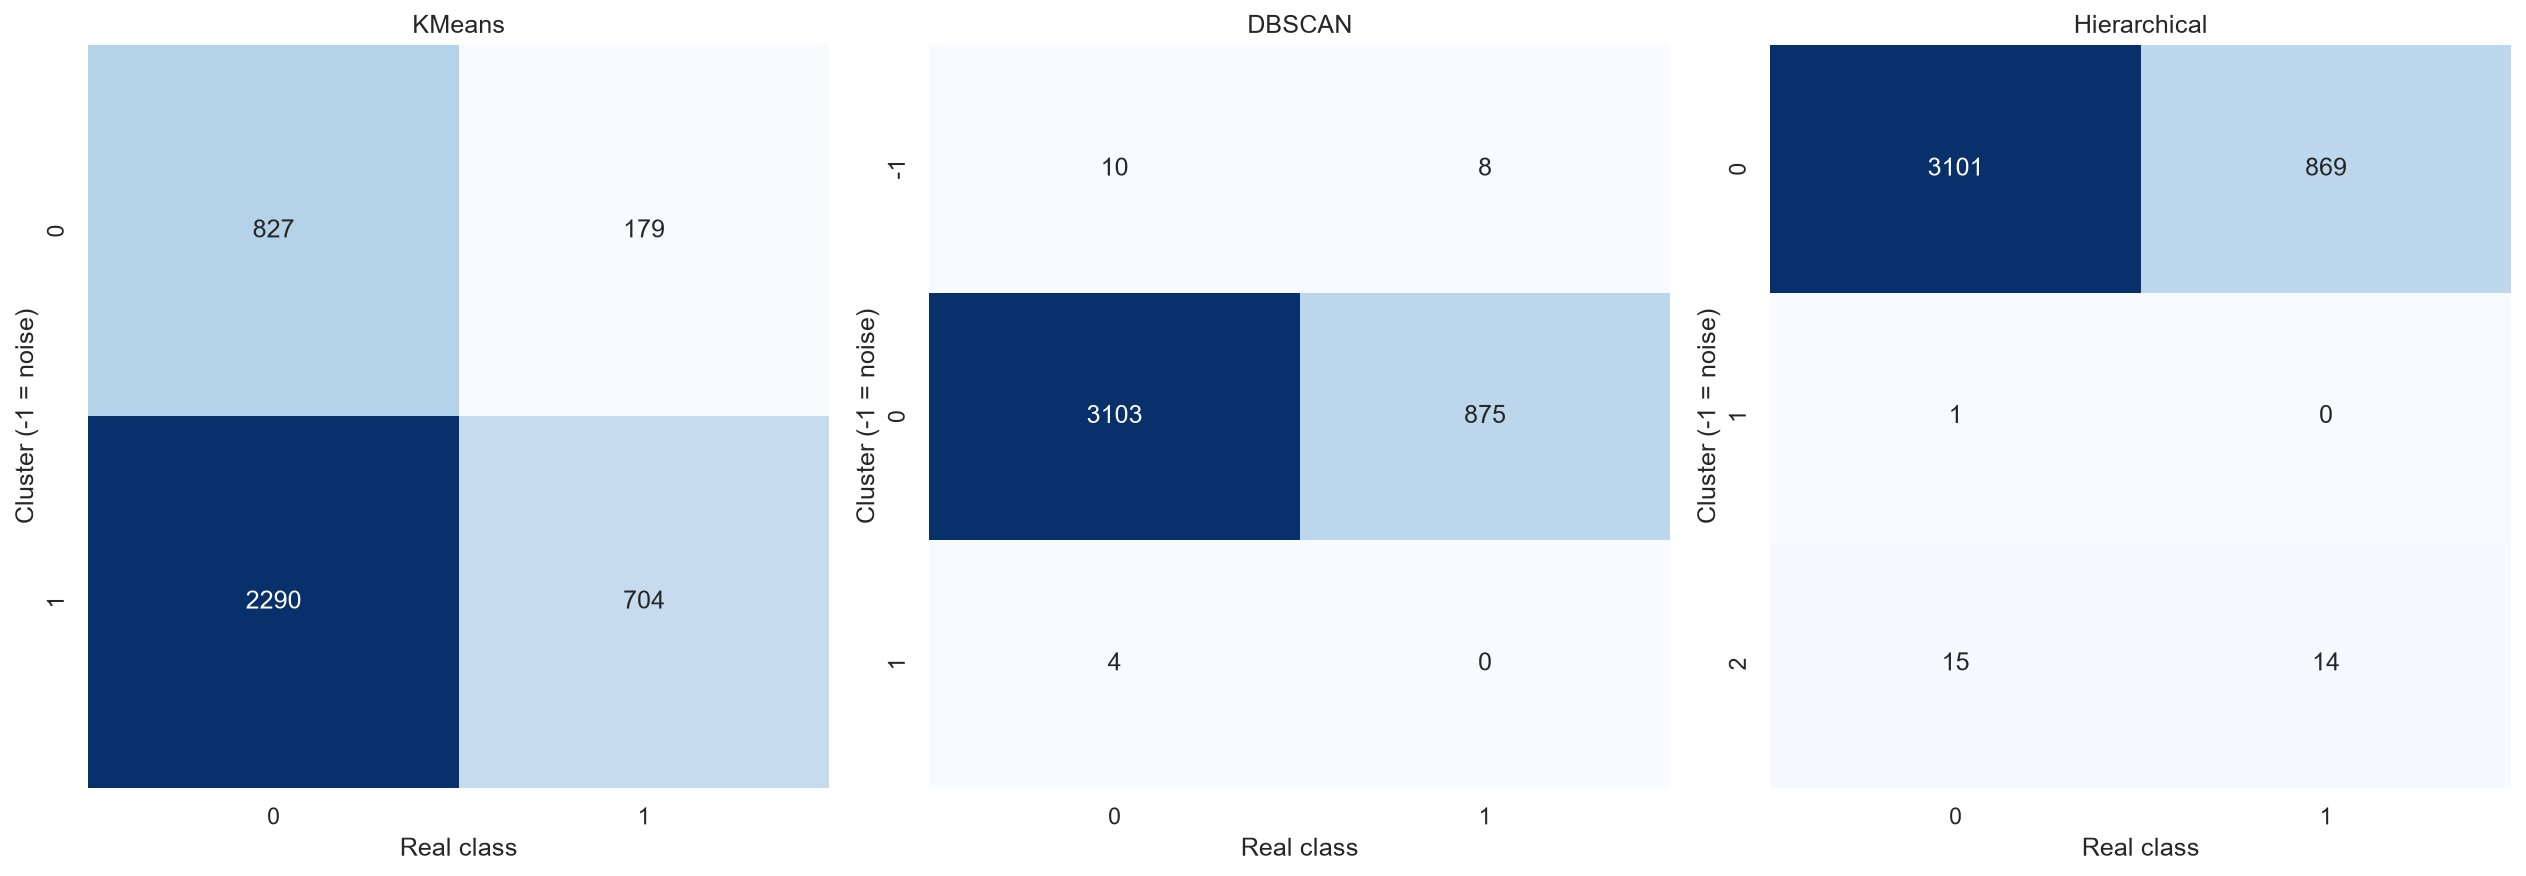

In [54]:
display(Image(filename=str(LAB / 'reports/classes_comparison.png')))

### dendrogram

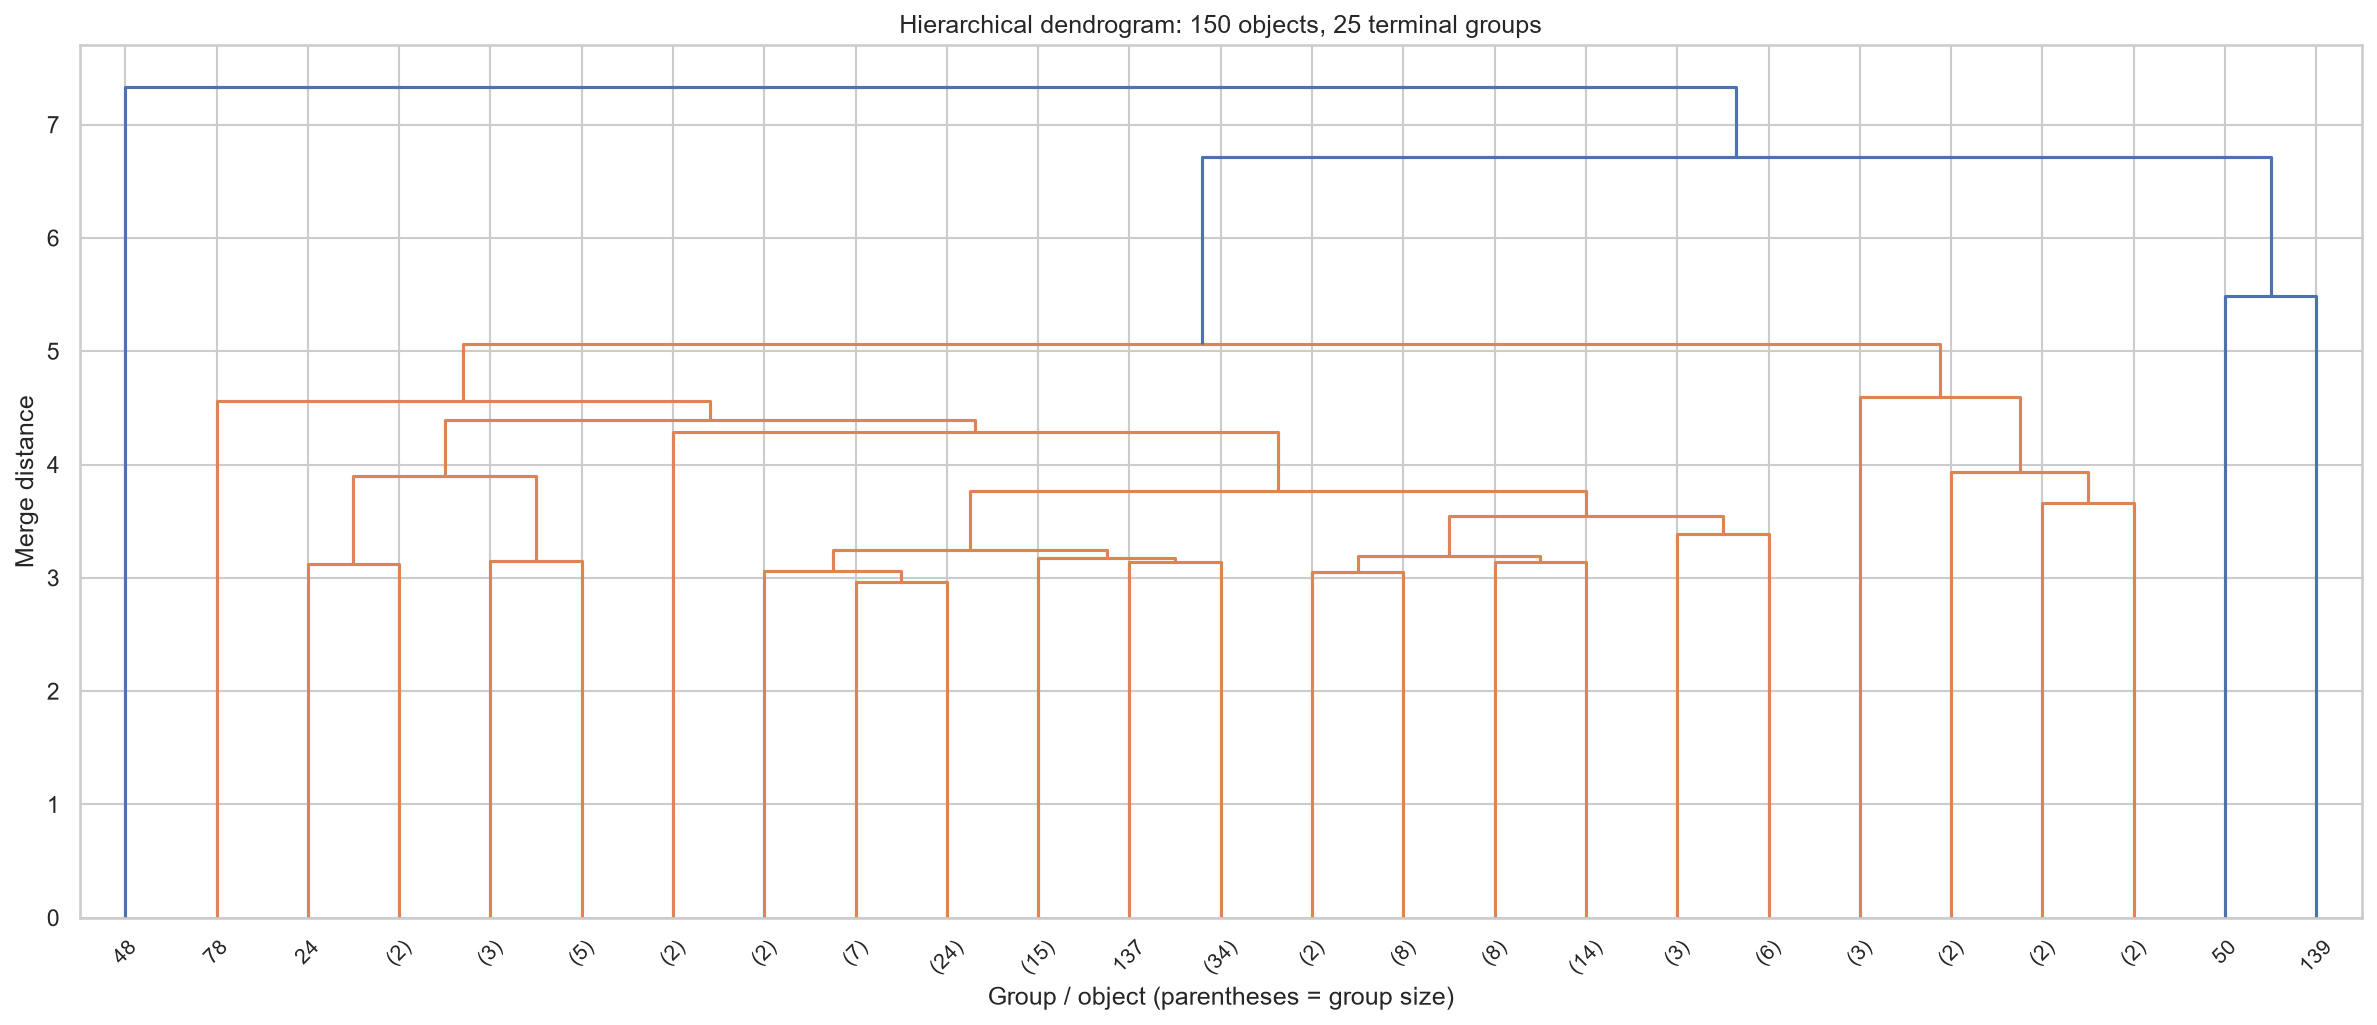

In [56]:
display(Image(filename=str(LAB / 'reports/dendrogram.png')))

### partitions_pca

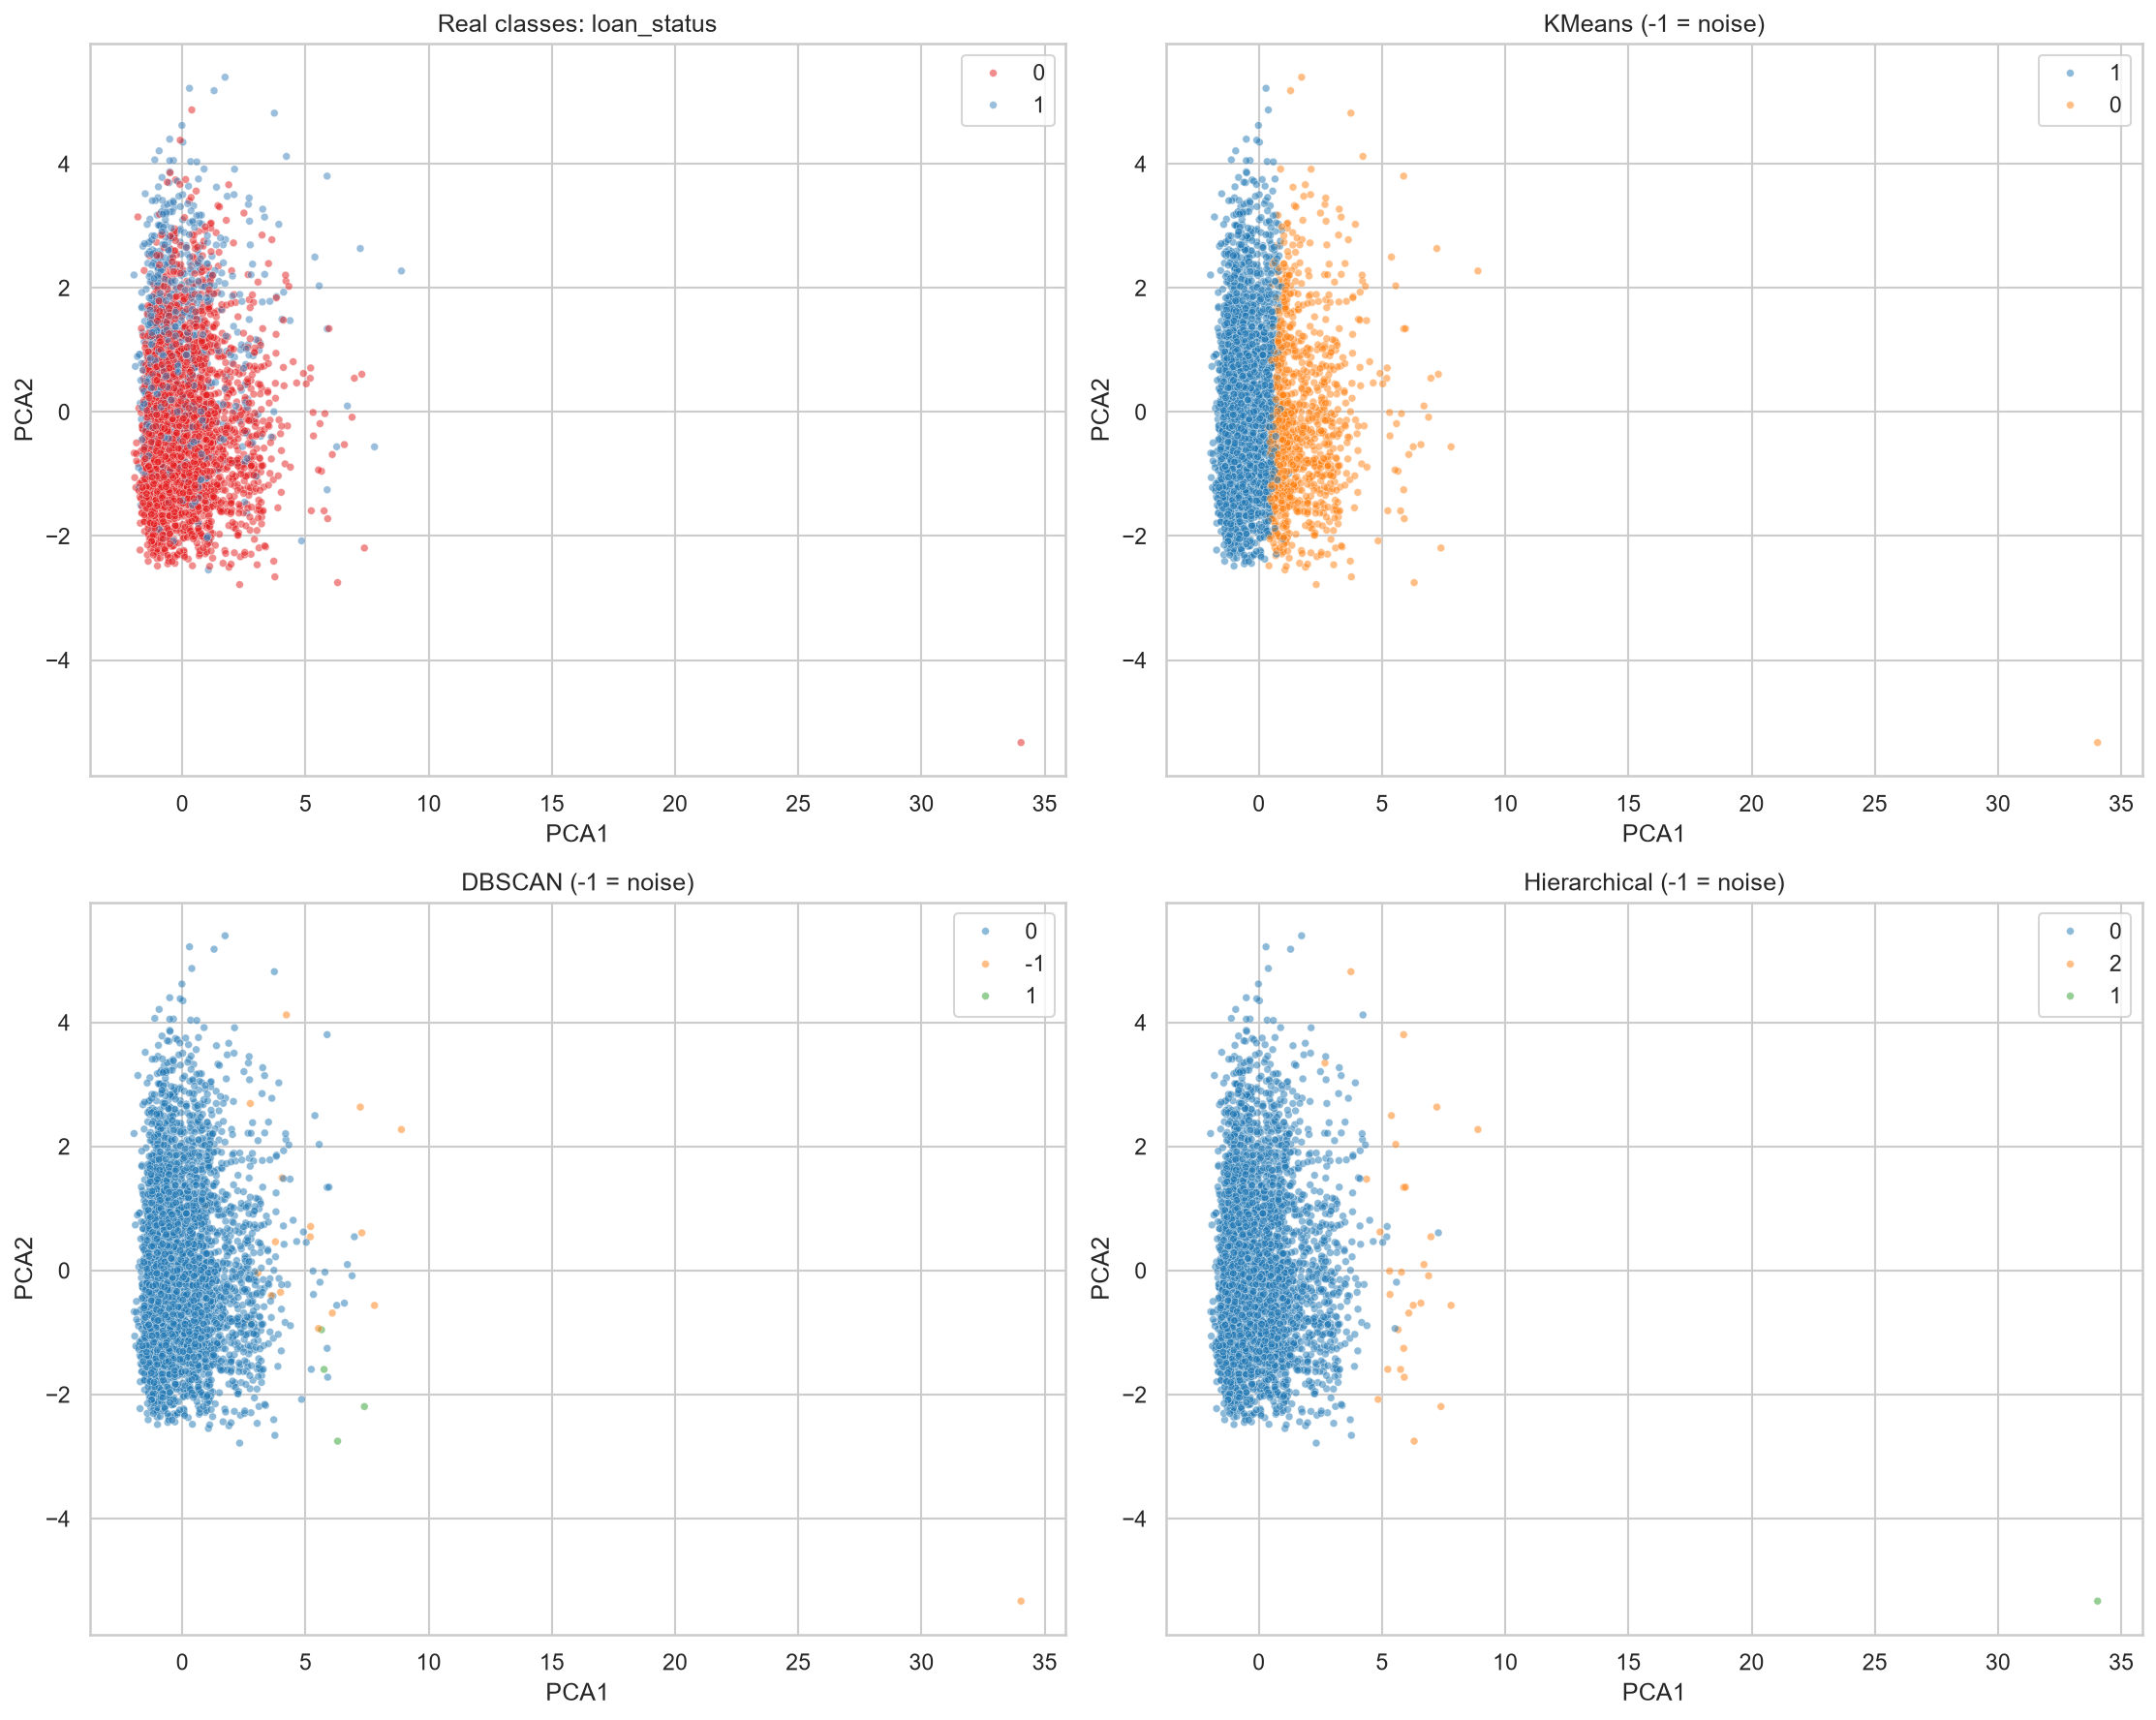

In [58]:
display(Image(filename=str(LAB / 'reports/partitions_pca.png')))

## Вывод
ARI и AMI около нуля: группы не воспроизводят дефолт. KMeans выделяет возрастные сегменты; DBSCAN и иерархический метод чувствительны к необычным наблюдениям. Высокий silhouette не гарантирует полезность групп.

Ограничения: сохранены аномалии; оценка относится к данному эксперименту и не доказывает переносимость на другие данные.